# Kalimantan and Sumatera FIRMS fire alerts and fire count grid, August to October 2026

Plots the provinces of Kalimantan and mainland Sumatera on a basemap, the FIRMS fire alerts made by `job/firms` (VIIRS and MODIS near real time, clipped to each province), the fire count grids made by `job/firms_grid` (number of alerts per cell, with sea, outside the provinces and WorldCover water masked), and the number of alerts per regency and city (admin level 2). Both regions are shown together on each map.

In [1]:
import os

os.chdir(os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebook" else os.getcwd())

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling
from dotenv import load_dotenv
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# override=True so the .env credentials win over anything already in the environment
load_dotenv(override=True)

# Lower resolution figures, keeps the notebook small
plt.rcParams["figure.dpi"] = 60

AOI_URL = "/vsicurl/https://storage.googleapis.com/gee-ramiqcom-bucket/admin/indonesia_adm_level_1.fgb"
AOI2_URL = "/vsicurl/https://storage.googleapis.com/gee-ramiqcom-bucket/admin/indonesia_adm_level_2.fgb"

# Kalimantan and mainland Sumatera provinces, the same as job/firms
AOI_FILTER = (
    "WADMPR LIKE 'Kalimantan%' OR WADMPR LIKE 'Sumatera%' "
    "OR WADMPR IN ('Aceh', 'Riau', 'Jambi', 'Bengkulu', 'Lampung')"
)
CLOUD_PREFIX = "gs://gee-ramiqcom-s4g-bucket/forest_fire_indonesian_2026"
DATE_NAME = "2026-08_2026-10"
GRID_PATHS = {
    region: f"{CLOUD_PREFIX}/firms_grid/{region}_{DATE_NAME}.tif" for region in ["kalimantan", "sumatera"]
}
GFC_PREFIX = f"{CLOUD_PREFIX}/jrc_gfc_2020"
PLACES_URL = "/vsicurl/https://storage.googleapis.com/gee-ramiqcom-s4g-bucket/forest_fire_indonesian_2026/urban/ne_10m_populated_places.fgb"
# Populated places shown on the maps
MIN_POPULATION = 1_000_000
# Wide figure, both regions side by side span about twice as much longitude as latitude
FIGSIZE = (22, 11)

## Map helpers

In [2]:
def add_lonlat(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"))
    ax.tick_params(labelsize=8)
    ax.grid(color="grey", linewidth=0.4, alpha=0.6, linestyle="--")


def add_north_arrow(ax, x=0.94, y=0.92):
    ax.annotate(
        "N",
        xy=(x, y),
        xytext=(x, y - 0.1),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(facecolor="black", edgecolor="white", width=4, headwidth=12),
    )


def add_scalebar(ax, x=0.05, y=0.05):
    # Axes are in degrees, so convert km to degrees of longitude at the map's center latitude
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    km_per_deg = 111.32 * np.cos(np.radians((ymin + ymax) / 2))
    width_km = (xmax - xmin) * km_per_deg
    length_km = next(n for n in (500, 200, 100, 50, 20, 10, 5, 2, 1, 0.5) if n <= width_km / 4)
    length_deg = length_km / km_per_deg

    x0 = xmin + x * (xmax - xmin)
    y0 = ymin + y * (ymax - ymin)
    height = (ymax - ymin) * 0.012
    for i in range(2):
        ax.add_patch(
            plt.Rectangle(
                (x0 + i * length_deg / 2, y0),
                length_deg / 2,
                height,
                facecolor="black" if i == 0 else "white",
                edgecolor="black",
                linewidth=0.8,
            )
        )
    for frac in (0, 0.5, 1):
        ax.text(
            x0 + frac * length_deg,
            y0 + height * 1.6,
            f"{length_km * frac:g}",
            ha="center",
            va="bottom",
            fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
        )
    ax.text(x0 + length_deg + (xmax - xmin) * 0.01, y0, "km", va="bottom", fontsize=8)


def set_extent(ax, gdf, pad_frac=0.03):
    xmin, ymin, xmax, ymax = gdf.total_bounds
    pad = pad_frac * max(xmax - xmin, ymax - ymin)
    ax.set_xlim(xmin - pad, xmax + pad)
    ax.set_ylim(ymin - pad, ymax + pad)


def add_basemap(ax, zoom_offset=1, **kwargs):
    # Light hillshade, one zoom level more detailed than contextily picks for the map extent (axes in degrees)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    zoom = cx.tile._calculate_zoom(xmin, ymin, xmax, ymax) + zoom_offset
    cx.add_basemap(
        ax, crs="EPSG:4326", source=cx.providers.Esri.WorldShadedRelief, zoom=zoom, attribution_size=6, **kwargs
    )


def decorate(ax, title):
    add_lonlat(ax)
    add_north_arrow(ax)
    add_scalebar(ax)
    ax.set_title(title)

## 1. Kalimantan and Sumatera provinces

Province boundaries from the Indonesian admin level 1 file, the same source and filter as the jobs. The file stores each province as many polygon parts, dissolved here into one shape per province. Kepulauan Riau and Kepulauan Bangka Belitung are not included.

In [3]:
provinces = gpd.read_file(AOI_URL, where=AOI_FILTER, columns=["KDPPUM", "WADMPR"])
provinces = provinces.dissolve(by=["KDPPUM", "WADMPR"]).reset_index().to_crs("EPSG:4326")
provinces["province"] = provinces["WADMPR"].str.lower().str.replace(" ", "_")
provinces[["KDPPUM", "WADMPR"]]

,KDPPUM,WADMPR
0,11,Aceh
1,12,Sumatera Utara
2,13,Sumatera Barat
3,14,Riau
4,15,Jambi
5,16,Sumatera Selatan
6,17,Bengkulu
7,18,Lampung
8,61,Kalimantan Barat
9,62,Kalimantan Tengah


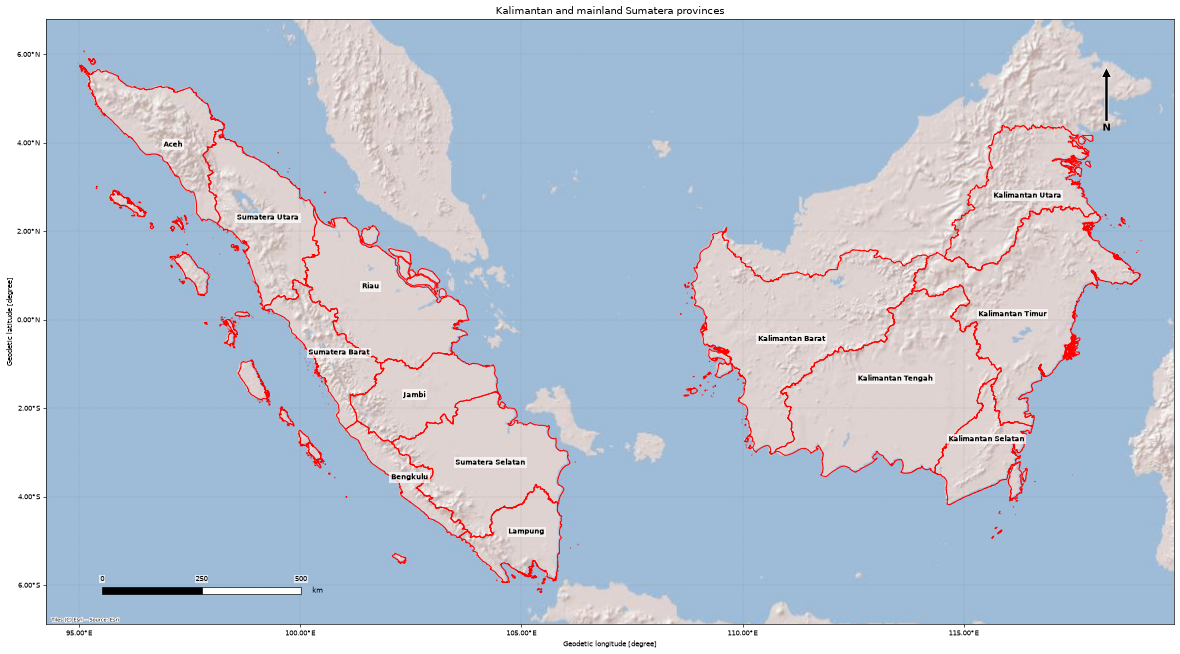

In [4]:
fig, ax = plt.subplots(figsize=FIGSIZE)

provinces.boundary.plot(ax=ax, color="red", linewidth=1.2)
for _, row in provinces.iterrows():
    point = row.geometry.representative_point()
    ax.text(
        point.x,
        point.y,
        row["WADMPR"],
        ha="center",
        fontsize=8,
        fontweight="bold",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=2),
    )

set_extent(ax, provinces)
add_basemap(ax)
decorate(ax, "Kalimantan and mainland Sumatera provinces")

plt.tight_layout()
plt.show()

## 2. FIRMS fire alerts, forest and large cities

All alerts from the province files. Each point is the centre of a satellite pixel with an active fire detection (375 m for VIIRS, 1 km for MODIS), not a burned area. MODIS near real time has no data for early August, so MODIS points cover only part of the period.

Forest is the JRC Global Forest Cover 2020 v4 made by `job/jrc_gfc_2020` (100 m per province, European Commission, CC BY 4.0), read here at about 1 km with the most common class per cell, which is enough at this map scale. Forest in 2020 does not mean forest during the 2026 fires. Cities are the Natural Earth populated places with a population (`POP_MAX`, the metropolitan estimate of the dataset) above 1 million, including the ones outside the provinces for orientation.

In [5]:
firms = pd.concat(
    [
        gpd.read_file(
            f"{CLOUD_PREFIX}/firms/{province}_{DATE_NAME}.fgb", columns=["acq_date", "instrument", "satellite"]
        ).assign(province=province)
        for province in provinces["province"]
    ],
    ignore_index=True,
)
firms = gpd.GeoDataFrame(firms, crs="EPSG:4326")

print(f"{len(firms):,} alerts, {firms['acq_date'].min()} to {firms['acq_date'].max()}")
firms.groupby(["province", "instrument"]).size().unstack(fill_value=0)

1,142,979 alerts, 2026-08-01 to 2026-10-31


instrument,MODIS,VIIRS
province,,
aceh,8,1632
bengkulu,54,1428
jambi,1450,20036
kalimantan_barat,9260,220986
kalimantan_selatan,4049,80366
kalimantan_tengah,29040,507408
kalimantan_timur,5728,90828
kalimantan_utara,200,8201
lampung,1190,17449


In [6]:
# Forest per province, read at about 1 km (10 times coarser than the 100 m files) to keep memory low
GFC_SCALE = 10

forest_layers = []
for province in provinces["province"]:
    with rasterio.open(f"{GFC_PREFIX}/{province}.tif") as src:
        shape = (src.height // GFC_SCALE, src.width // GFC_SCALE)
        # The nodata (255, outside the province) is left out of the most common class
        gfc = src.read(1, out_shape=shape, resampling=Resampling.mode, masked=True)
        bounds = src.bounds
    forest_layers.append((gfc.filled(0) == 1, (bounds.left, bounds.right, bounds.bottom, bounds.top)))

print(f"{len(forest_layers)} forest layers, {sum(forest.mean() * forest.size for forest, _ in forest_layers):,.0f} forest cells of about 1 km")

# Large cities within the map, also outside the provinces for orientation
xmin, ymin, xmax, ymax = provinces.total_bounds
pad = 0.03 * max(xmax - xmin, ymax - ymin)
cities = gpd.read_file(
    PLACES_URL, bbox=(xmin - pad, ymin - pad, xmax + pad, ymax + pad), columns=["NAME", "ADM0NAME", "POP_MAX"]
)
cities = cities[cities["POP_MAX"] > MIN_POPULATION].sort_values("POP_MAX", ascending=False)
# Drop cities within 0.5 degree (about 55 km) of a larger one, Bekasi is part of Greater Jakarta
kept = []
for index, city in cities.iterrows():
    if all(city.geometry.distance(cities.loc[other].geometry) > 0.5 for other in kept):
        kept.append(index)
cities = cities.loc[kept]
cities[["NAME", "ADM0NAME", "POP_MAX"]]

13 forest layers, 557,471 forest cells of about 1 km


,NAME,ADM0NAME,POP_MAX
12,Jakarta,Indonesia,9125000
39,Singapore,Singapore,5183700
63,George Town,Malaysia,2500000
56,Medan,Indonesia,2115000
45,Palembang,Indonesia,1749000
78,Kuala Lumpur,Malaysia,1448000
14,Makassar,Indonesia,1262000


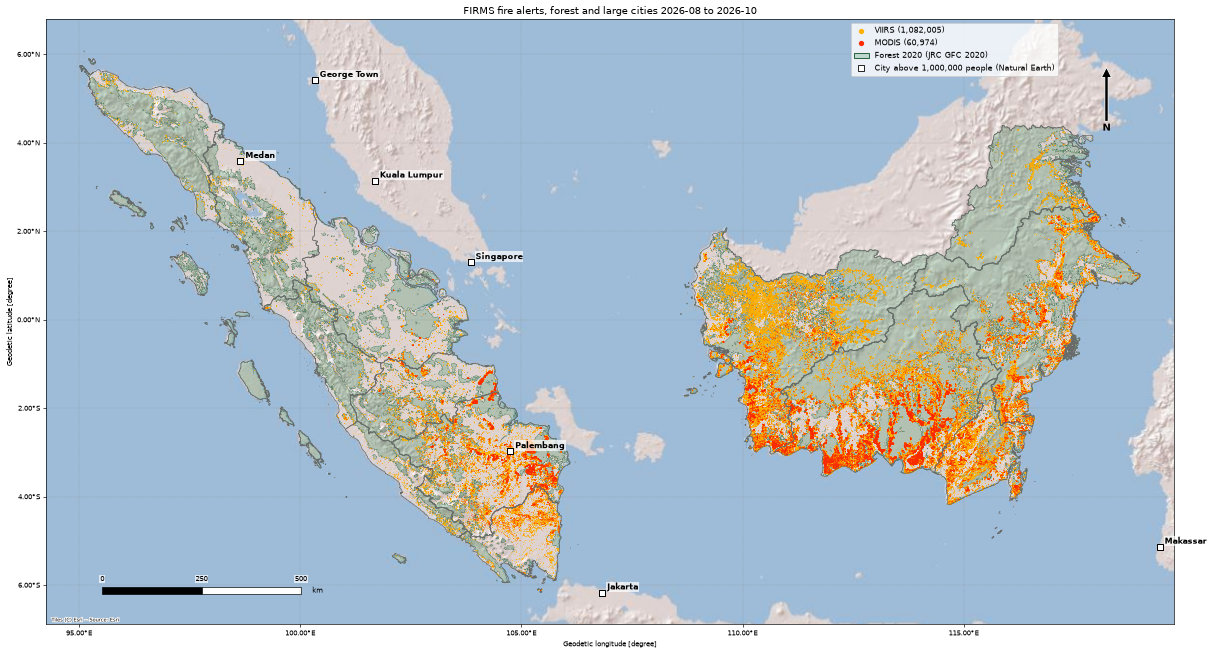

In [7]:
INSTRUMENT_COLORS = {"VIIRS": "#ffb000", "MODIS": "#ff2a00"}
FOREST_STYLE = dict(face="#2e8b57", edge="#0b4d23", alpha=0.25)
CITY_STYLE = dict(marker="s", size=40, face="white", edge="black")


def add_forest(ax, zorder=2):
    # Forest as a low opacity fill with a darker outline along its edge
    for forest, extent in forest_layers:
        ax.imshow(
            np.ma.masked_where(~forest, forest),
            extent=extent,
            cmap=ListedColormap([FOREST_STYLE["face"]]),
            alpha=FOREST_STYLE["alpha"],
            interpolation="nearest",
            zorder=zorder,
        )
        ax.contour(
            forest.astype("uint8"),
            levels=[0.5],
            extent=extent,
            origin="upper",
            colors=FOREST_STYLE["edge"],
            linewidths=0.3,
            zorder=zorder,
        )


def add_cities(ax, zorder=6):
    ax.scatter(
        cities.geometry.x,
        cities.geometry.y,
        s=CITY_STYLE["size"],
        marker=CITY_STYLE["marker"],
        facecolor=CITY_STYLE["face"],
        edgecolor=CITY_STYLE["edge"],
        linewidths=1.2,
        zorder=zorder,
    )
    for _, city in cities.iterrows():
        ax.annotate(
            city["NAME"],
            (city.geometry.x, city.geometry.y),
            xytext=(6, 4),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
            zorder=zorder,
        )


def context_handles():
    return [
        Patch(
            facecolor=FOREST_STYLE["face"] + "40",
            edgecolor=FOREST_STYLE["edge"],
            label="Forest 2020 (JRC GFC 2020)",
        ),
        Line2D(
            [],
            [],
            linestyle="none",
            marker=CITY_STYLE["marker"],
            markersize=7,
            markerfacecolor=CITY_STYLE["face"],
            markeredgecolor=CITY_STYLE["edge"],
            label=f"City above {MIN_POPULATION:,} people (Natural Earth)",
        ),
    ]


fig, ax = plt.subplots(figsize=FIGSIZE)

add_forest(ax)
# Scatter on the raw coordinates, much faster than GeoDataFrame.plot for millions of points
for instrument, color in INSTRUMENT_COLORS.items():
    points = firms[firms["instrument"] == instrument]
    ax.scatter(
        points.geometry.x,
        points.geometry.y,
        s=0.3,
        color=color,
        linewidths=0,
        label=f"{instrument} ({len(points):,})",
        rasterized=True,
        zorder=4,
    )
provinces.boundary.plot(ax=ax, color="dimgrey", linewidth=0.8, zorder=5)
add_cities(ax)

set_extent(ax, provinces)
add_basemap(ax, zorder=1)
decorate(ax, f"FIRMS fire alerts, forest and large cities {DATE_NAME.replace('_', ' to ')}")

handles, _ = ax.get_legend_handles_labels()
legend = ax.legend(handles=handles + context_handles(), loc="upper right", bbox_to_anchor=(0.9, 1), fontsize=9)
# The alert points are tiny on the map, larger in the legend so their color can be read
for handle in legend.legend_handles[: len(INSTRUMENT_COLORS)]:
    handle.set_sizes([40])

plt.tight_layout()
plt.show()

## 3. Fire count grid

Number of FIRMS alerts per grid cell from `job/firms_grid`, one grid per region drawn on the same map with one color scale. The grid count only includes alerts within half a cell from the cell centre, so it counts fewer alerts than the points above. Cells with no alerts (0) are shown as no data, as are the masked sea, outside the provinces and WorldCover water cells. Log color scale because a few cells have far more alerts than the rest.

The 2020 forest and the cities above 1 million people are drawn under and over the grid as in the map above.

In [8]:
grids = {}
for region, path in GRID_PATHS.items():
    with rasterio.open(path) as src:
        grid = src.read(1)
        bounds = src.bounds
        nodata = src.nodata
        resolution = src.res

    # Masked cells and cells without alerts are not shown
    fire_count = np.ma.masked_where((grid == nodata) | (grid == 0), grid)
    grids[region] = (fire_count, (bounds.left, bounds.right, bounds.bottom, bounds.top))

    print(
        f"{region}: cell size {resolution[0]:.4f}°, {fire_count.count():,} cells with alerts, "
        f"{int(fire_count.sum()):,} alerts counted, max {fire_count.max()} per cell"
    )

# One color scale for both regions so they can be compared
grid_max = max(fire_count.max() for fire_count, _ in grids.values())

kalimantan: cell size 0.0090°, 88,055 cells with alerts, 749,840 alerts counted, max 721 per cell
sumatera: cell size 0.0090°, 23,915 cells with alerts, 146,599 alerts counted, max 469 per cell


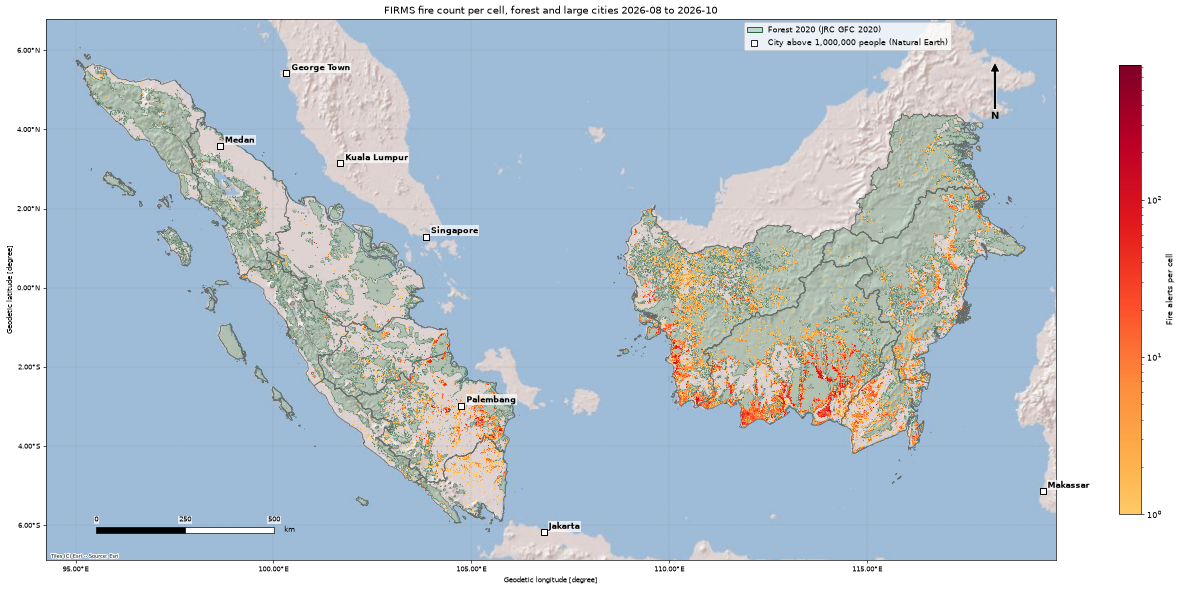

In [9]:
# YlOrRd without its near white start, so cells with few alerts stay visible on the light basemap
grid_cmap = ListedColormap(plt.get_cmap("YlOrRd")(np.linspace(0.3, 1, 256)))

fig, ax = plt.subplots(figsize=FIGSIZE)

add_forest(ax, zorder=2)
for fire_count, extent in grids.values():
    image = ax.imshow(
        fire_count,
        extent=extent,
        cmap=grid_cmap,
        norm=LogNorm(vmin=1, vmax=grid_max),
        interpolation="nearest",
        zorder=3,
    )
provinces.boundary.plot(ax=ax, color="dimgrey", linewidth=0.8, zorder=4)
add_cities(ax)

set_extent(ax, provinces)
add_basemap(ax, zorder=1)
decorate(ax, f"FIRMS fire count per cell, forest and large cities {DATE_NAME.replace('_', ' to ')}")
fig.colorbar(image, ax=ax, shrink=0.7, label="Fire alerts per cell")
ax.legend(handles=context_handles(), loc="upper right", bbox_to_anchor=(0.9, 1), fontsize=9)

plt.tight_layout()
plt.show()

## 4. Fire alerts per regency and city

Regency and city boundaries (kabupaten and kota) from the Indonesian admin level 2 file, with the same province filter. Each FIRMS alert is assigned to the regency it falls in, so every alert is counted, unlike the grid above. Regencies differ a lot in size, so the alerts per 100 km² are shown below the total count, with the area computed in an equal area projection (EPSG:6933). A few unnamed admin level 2 polygons are dropped by the dissolve.

In [10]:
regencies = gpd.read_file(AOI2_URL, where=AOI_FILTER, columns=["KDPKAB", "KDPPUM", "WADMKK", "WADMPR"])
regencies = regencies.dissolve(by=["KDPKAB", "KDPPUM", "WADMKK", "WADMPR"]).reset_index().to_crs("EPSG:4326")

alerts = firms[["instrument", "geometry"]].sjoin(regencies[["KDPKAB", "geometry"]], predicate="within")
counts = alerts.groupby(["KDPKAB", "instrument"]).size().unstack(fill_value=0)

regencies = regencies.merge(counts, left_on="KDPKAB", right_index=True, how="left")
regencies[["VIIRS", "MODIS"]] = regencies[["VIIRS", "MODIS"]].fillna(0).astype(int)
regencies["alerts"] = regencies["VIIRS"] + regencies["MODIS"]
regencies["area_km2"] = regencies.to_crs("EPSG:6933").area / 1e6
regencies["alerts_per_100km2"] = regencies["alerts"] / regencies["area_km2"] * 100

# Alerts near the coast or on borders can fall outside every admin level 2 polygon
print(f"{len(regencies)} regencies and cities, {regencies['alerts'].sum():,} of {len(firms):,} alerts assigned")
regencies.sort_values("alerts", ascending=False)[
    ["WADMKK", "WADMPR", "VIIRS", "MODIS", "alerts", "area_km2", "alerts_per_100km2"]
].head(20).round(1)

196 regencies and cities, 1,142,979 of 1,142,979 alerts assigned


,WADMKK,WADMPR,VIIRS,MODIS,alerts,area_km2,alerts_per_100km2
143,Ketapang,Kalimantan Barat,131369,6621,137990,30018.7,459.7
164,Pulang Pisau,Kalimantan Tengah,97928,6118,104046,9650.9,1078.1
156,Kapuas,Kalimantan Tengah,73694,3912,77606,17041.2,455.4
155,Kotawaringin Timur,Kalimantan Tengah,71439,3827,75266,15543.8,484.2
160,Seruyan,Kalimantan Tengah,65397,3960,69357,15215.2,455.8
99,Ogan Komering Ilir,Sumatera Selatan,54925,4494,59419,17071.3,348.1
159,Katingan,Kalimantan Tengah,48447,3039,51486,20382.3,252.6
154,Kotawaringin Barat,Kalimantan Tengah,48409,2997,51406,9480.3,542.2
167,Kota Palangkaraya,Kalimantan Tengah,46344,1784,48128,2848.7,1689.5
181,Paser,Kalimantan Timur,23770,1665,25435,10767.4,236.2


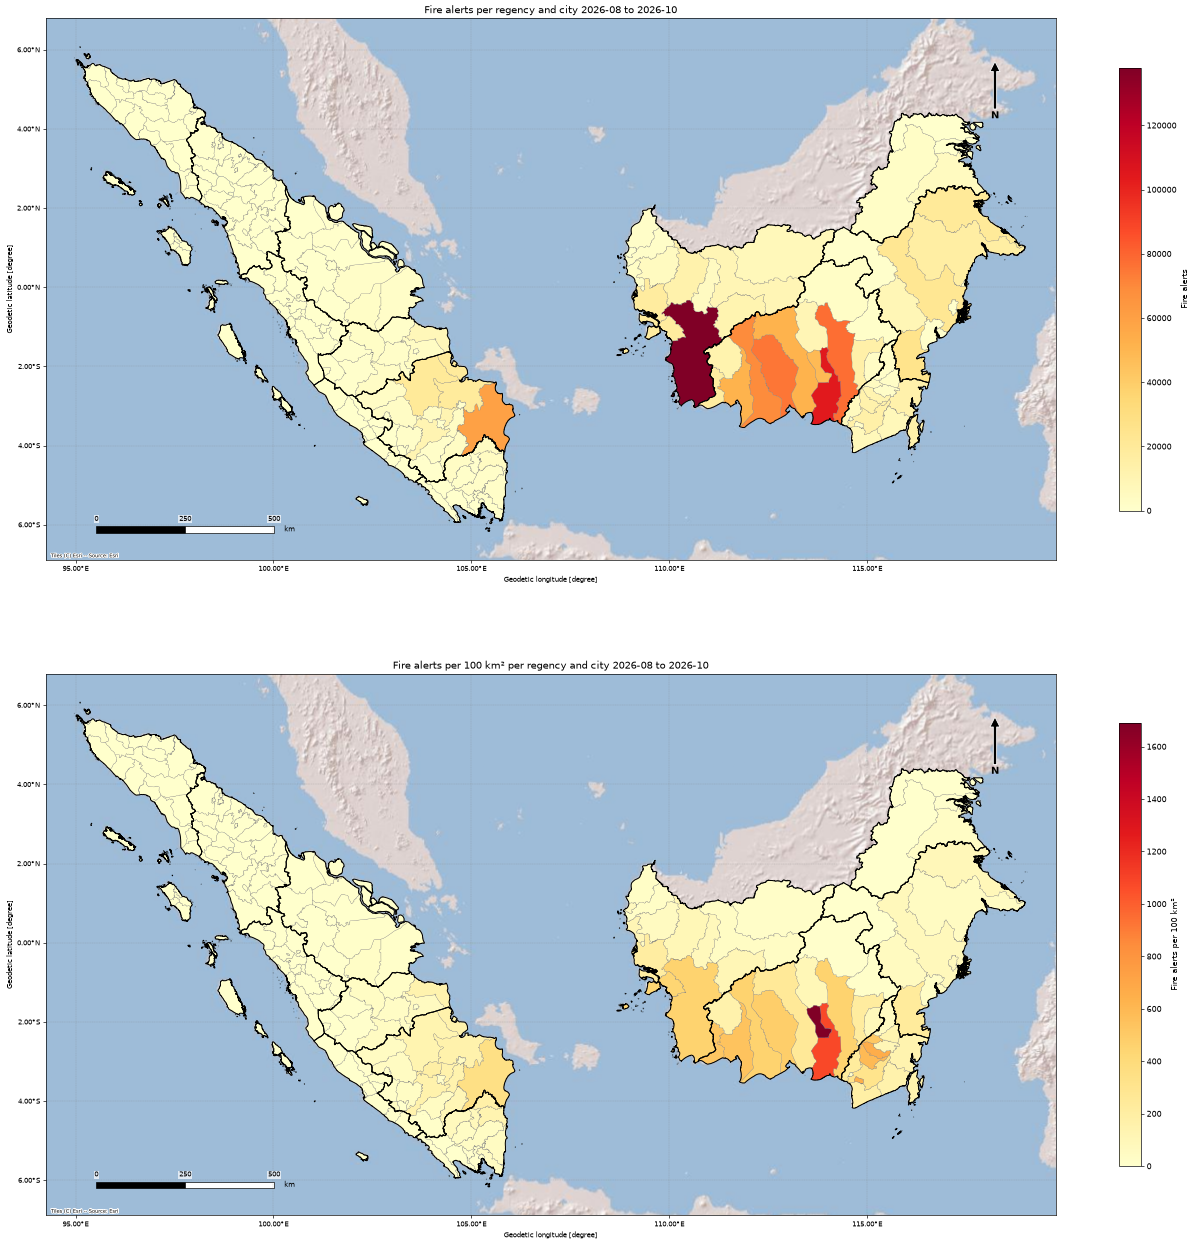

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(FIGSIZE[0], FIGSIZE[1] * 2))

for ax, (column, label, cmap) in zip(
    axes,
    [
        ("alerts", "Fire alerts", "YlOrRd"),
        ("alerts_per_100km2", "Fire alerts per 100 km²", "YlOrRd"),
    ],
):
    regencies.plot(
        ax=ax,
        column=column,
        cmap=cmap,
        edgecolor="grey",
        linewidth=0.3,
        legend=True,
        legend_kwds=dict(shrink=0.7, label=label),
        zorder=2,
    )
    provinces.boundary.plot(ax=ax, color="black", linewidth=1.2, zorder=3)

    set_extent(ax, provinces)
    add_basemap(ax, zorder=1)
    decorate(ax, f"{label} per regency and city {DATE_NAME.replace('_', ' to ')}")

plt.tight_layout()
plt.show()